In [27]:
import numpy as np
import pandas as pd

In [45]:
data=pd.read_csv('nyc_housing_base.csv')
data=data.dropna()
data.head()

,borough_x,block,lot,sale_price,zip_code,borough_y,yearbuilt,lotarea,bldgarea,resarea,comarea,unitsres,unitstotal,numfloors,latitude,longitude,landuse,bldgclass,building_age
0,1,400,11,280000,10009.0,MN,1900.0,2404.0,6875.0,6875.0,0.0,18.0,18.0,5.0,40.724415,-73.983891,2.0,C6,125.0
1,1,402,36,2000000,10009.0,MN,1900.0,1919.0,7810.0,6810.0,1000.0,8.0,10.0,5.0,40.724975,-73.981535,2.0,C4,125.0
2,1,402,60,3400000,10009.0,MN,1920.0,2150.0,6152.0,5352.0,800.0,8.0,9.0,5.0,40.725346,-73.983112,4.0,C7,105.0
3,1,404,42,4000000,10009.0,MN,1855.0,2369.0,6990.0,6990.0,0.0,10.0,10.0,5.0,40.727398,-73.980600,2.0,C4,170.0
4,1,372,55,655000,10009.0,MN,1920.0,5298.0,17990.0,17990.0,0.0,20.0,20.0,5.0,40.720621,-73.979534,2.0,C6,105.0


In [29]:
#x1=lot ,x2=building age,x3=total unnits,x4=no of floors,
#Y=sale price
#x..(n)*5
#y..n*1
#theta..5*1


In [30]:
def cal_z_score(x):
    m=data[x].mean()
    sd=data[x].std()
    zx=(data[x]-m)/sd
    return zx
    
    


In [31]:
newf=cal_z_score(['lot','building_age','unitstotal','numfloors'])
ones = np.ones((newf.shape[0], 1))
newd=np.hstack((ones, newf))
y=data['sale_price'].to_numpy()
y=y.reshape(-1, 1)
y_mean = np.mean(y)
y_std = np.std(y)
y_scaled = (y - y_mean) / y_std
predictions = (newd @ theta) * y_std + y_mean

In [32]:
the=np.zeros((newd.shape[1],1))
lr=.01
m=len(y)

In [40]:
the=np.zeros((newd.shape[1],1))
lr=.01
m=len(y)
cost_history = []
for _ in range(1000):
    error = newd @ the - y_scaled
    gv = (newd.T @ (error)) / m
    cost = np.sum(error**2) / (2 * m)
    cost_history.append(cost)
    the = the - lr * gv
    
print('Theta')
print(the)
print('Cost')
print(cost)

   
        


Theta
[[-8.60180410e-17]
 [ 4.16997080e-03]
 [ 1.29521313e-01]
 [-1.55414854e-01]
 [ 9.28353089e-02]]
Cost
0.48301686728573273


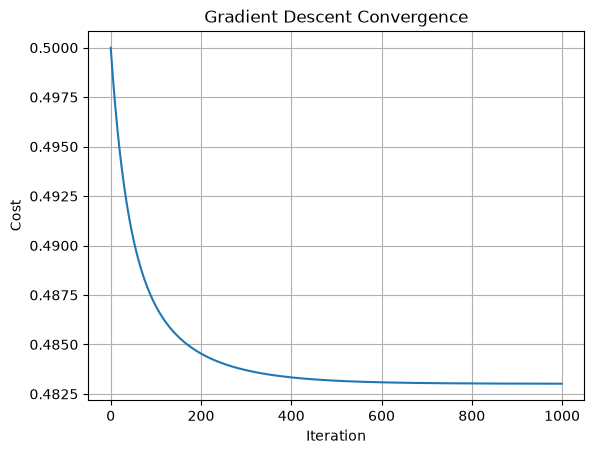

In [44]:
import matplotlib.pyplot as plt

plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.grid(True)
plt.show()